In [1]:

# ======================================================================
# Adım 1: Kütüphaneler ve yeni kavramlar
# ======================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Hazır")


# ======================================================================
# Adım 2: Veri setini oluşturma
# ======================================================================
rng = np.random.default_rng(42)
n = 300
saat = rng.uniform(0, 10, n).round(1)
devamsizlik = rng.integers(0, 13, n)
z = -3.0 + 0.8 * saat - 0.35 * devamsizlik
p = 1 / (1 + np.exp(-z))
gecti = rng.binomial(1, p)
df = pd.DataFrame({"Calisma_Saati": saat, "Devamsizlik_Gun": devamsizlik, "Gecti": gecti})
print(df.head())
print("\nGeçen oranı:", round(df["Gecti"].mean(), 3))
print(df["Gecti"].value_counts())



Hazır
   Calisma_Saati  Devamsizlik_Gun  Gecti
0            7.7                8      1
1            4.4               10      0
2            8.6                9      0
3            7.0                1      1
4            0.9               10      0

Geçen oranı: 0.347
Gecti
0    196
1    104
Name: count, dtype: int64


In [2]:
df

,Calisma_Saati,Devamsizlik_Gun,Gecti
0,7.7,8,1
1,4.4,10,0
2,8.6,9,0
3,7.0,1,1
4,0.9,10,0
...,...,...,...
295,9.0,7,1
296,9.8,6,1
297,8.0,0,1
298,7.8,0,1


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Calisma_Saati,300.0,4.864000,2.904956,0.1,2.3,4.8,7.525,9.9
Devamsizlik_Gun,300.0,6.196667,3.847162,0.0,3.0,6.5,10.000,12.0
Gecti,300.0,0.346667,0.476704,0.0,0.0,0.0,1.000,1.0


In [6]:
df["Gecti"].value_counts()

Gecti
0    196
1    104
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Calisma_Saati    300 non-null    float64
 1   Devamsizlik_Gun  300 non-null    int64  
 2   Gecti            300 non-null    int64  
dtypes: float64(1), int64(2)
memory usage: 7.2 KB


In [9]:
X=df.drop("Gecti",axis=1)
y=df["Gecti"]

In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.2,random_state=42)

In [11]:
scaler = StandardScaler()

In [12]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
print("Eğitimden öğrenilen ortalamalar:", scaler.mean_.round(2))
print("Ölçeklenmiş eğitim ortalaması:", X_train_scaled.mean(axis=0).round(2))

Eğitimden öğrenilen ortalamalar: [5.26 5.43]
Ölçeklenmiş eğitim ortalaması: [-0. -0.]


In [15]:
en_sik = y_train.mode()[0]
baseline_acc = (y_test == en_sik).mean()
print(f"Herkese '{en_sik}' dersek Accuracy: {baseline_acc:.2f}")

Herkese '0' dersek Accuracy: 0.67


In [17]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled,y_train)
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:,1]
print("İlk 5 test öğrencisi :")
print(pd.DataFrame({"Gercek": y_test.values[:5], "Gecme_Olasiligi": y_proba[:5].round(2), "Tahmin": y_pred[:5]}))
print("\nKatsayılar:", {k: round(float(v), 2) for k, v in zip(X.columns, model.coef_[0])})

İlk 5 test öğrencisi :
   Gercek  Gecme_Olasiligi  Tahmin
0       0             0.01       0
1       0             0.02       0
2       1             0.16       0
3       0             0.05       0
4       1             0.78       1

Katsayılar: {'Calisma_Saati': 1.85, 'Devamsizlik_Gun': -1.26}


In [18]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 2))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=["Kaldı", "Geçti"]))

Accuracy: 0.85

Confusion Matrix:
[[145  15]
 [ 20  60]]

               precision    recall  f1-score   support

       Kaldı       0.88      0.91      0.89       160
       Geçti       0.80      0.75      0.77        80

    accuracy                           0.85       240
   macro avg       0.84      0.83      0.83       240
weighted avg       0.85      0.85      0.85       240



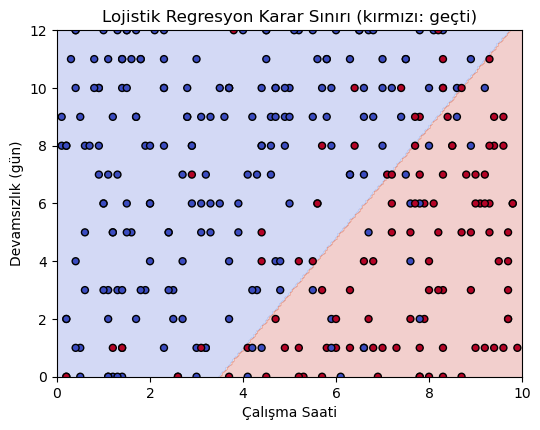

In [19]:
xx, yy = np.meshgrid(np.linspace(0, 10, 200), np.linspace(0, 12, 200))
grid = pd.DataFrame({"Calisma_Saati": xx.ravel(), "Devamsizlik_Gun": yy.ravel()})
zz = model.predict(scaler.transform(grid)).reshape(xx.shape)
plt.figure(figsize=(6, 4.5))
plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
plt.scatter(df["Calisma_Saati"], df["Devamsizlik_Gun"], c=df["Gecti"], cmap="coolwarm", edgecolor="k", s=25)
plt.xlabel("Çalışma Saati"); plt.ylabel("Devamsızlık (gün)")
plt.title("Lojistik Regresyon Karar Sınırı (kırmızı: geçti)")
plt.show()